# Select metamodel goals in the AoI buffer ring

Workflow:

1. Auto-crop the **world-scale** hindcast catalogs and land polygons down to this
   AoI (once per case) into a small `hindcasts-<case>` folder, then load **AoI**,
   **land**, and all hindcast coordinates catalogs from it.
2. Build the **inland buffer ring**: `ring = (AoI - AoI.buffer(-d)) - land`.
3. Place **random spaced targets** inside the ring (open water), then number them **clockwise along the AoI boundary** (starting at the westernmost point).
4. For each target, snap to the **nearest node in every hindcast** catalog.
5. (Optional) Filter out goals that are too far from any hindcast node.
6. Compute **adaptive open-sea propagation sectors** from the nearest **AoI boundary** point.
7. (Optional) Manually override goal directions, re-plot, and then save JSON + GeoPackage.

**Direction convention** (`bluemath_tk.core.operations`): all stored `angles` are **nautical**
wave-from directions, **clockwise from North** (`0°` = N, `90°` = E). Each goal has
`[left, right]` with `left < right` (clockwise sector boundaries). If the sector crosses
North, `left` is negative (e.g. `[-10, 50]` = 350°->50° clockwise). This matches WHACS
and SnapWave forcing; LHS samples `dir` in that range and normalizes with `% 360`.

**World master data**: `QGIS/HyWorld/hindcasts/` and `QGIS/HyWorld/land/` are
expected to hold the global hindcast node catalogs and a world coastline
(e.g. GSHHS). They're too large for git (`QGIS/` is in `.gitignore`) and too
slow to load directly in Python, so they live only on disk, however you
obtain them. This notebook reads only the small AoI-sized crop it needs from
them (`prepare_case_hindcasts`, below); the cropped `hindcasts-<case>/*.gpkg`
files it writes are small enough to drag-and-drop straight into QGIS.

In [13]:
import os
import sys

# Must run before any GDAL-touching import (geopandas/pyogrio, rasterio/rioxarray).
# When the kernel is launched without going through `conda activate` (e.g. VS
# Code's Jupyter extension), GDAL_DATA/PROJ_DATA are unset, and importing
# rioxarray/rasterio before geopandas.read_file() in that state leaves GDAL's
# data-path auto-discovery broken for pyogrio, raising:
#   ValueError: Found GDAL data directory at .../share/gdal but it does not
#   appear to correctly contain GDAL data files
# Setting these explicitly sidesteps the broken auto-discovery.
os.environ.setdefault("GDAL_DATA", os.path.join(sys.prefix, "share", "gdal"))
os.environ.setdefault("PROJ_DATA", os.path.join(sys.prefix, "share", "proj"))

import json

import geopandas as gpd
import pandas as pd
from bluemath_tk.waves.hywaves import sectors as hc
from utils.config import PATHS, resolve
from utils import viz as plot

## Parameters

In [14]:
buffer_distance_m = 5_000.0
min_spacing_m = 40_000.0

# Optional cap: drop goals if any hindcast snap distance exceeds this threshold.
# Set to None to disable filtering.
max_hindcast_distance_m = 60_000.0

sector_margin_deg = 5.0
random_seed = 42

geo_crs = "EPSG:4326"
work_crs = "EPSG:32632"  # TODO: UTM CRS for your region

# World-scale masters (not in git -- see the intro cell). Cropped once per case
# into hindcasts_dir by prepare_case_hindcasts(), below.
world_hindcasts_dir = "/lustre/geocean/DATA/GEOOCEAN/HyGloW/hindcasts"
world_land_path = (
    "/lustre/geocean/DATA/GEOOCEAN/gshhg-shp-2.3.7/GSHHS_shp/f/GSHHS_f_L1.shp"
)


# The per-case QGIS project (and its cropped hindcasts-<case> cache) now
# lives in the repo-level shared `data/QGIS/` folder (`CASE_DIR.parent /
# "data" / "QGIS"`), not directly under `DEME/QGIS/` -- see the "Shared
# input data" note in the root CLAUDE.md. This is unrelated to
# world_hindcasts_dir/world_land_path above, which point at the separate
# HyGloW template repo's global master catalogs, not this project's data/.
hindcasts_dir = "inputs/Hindcasts"
land_path = hindcasts_dir + "/land.gpkg"

# Crop padding around the AoI bbox -- must cover max_hindcast_distance_m.
hindcasts_buffer_km = 10  # max(150.0, (max_hindcast_distance_m or 0) / 1_000 * 1.2)

from utils.config import SIMULATIONS

goals_out_path = resolve(SIMULATIONS["goals_file"])
goals_gpkg_path = goals_out_path.with_suffix(".gpkg")

print(f"AoI       : {resolve(PATHS['aoi_file'])}")
print(f"hindcasts : {hindcasts_dir}")
print(f"land      : {land_path}")
print(f"json      : {goals_out_path}")
print(f"gpkg      : {goals_gpkg_path}")
print(f"min dist  : {min_spacing_m} m")
print(f"max dist  : {max_hindcast_distance_m} m")

AoI       : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/AoI_Polygons/Netherlands_AoI.shp
hindcasts : inputs/Hindcasts
land      : inputs/Hindcasts/land.gpkg
json      : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/Goals/Netherlands_Goals.json
gpkg      : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/Goals/Netherlands_Goals.gpkg
min dist  : 40000.0 m
max dist  : 60000.0 m


## Prepare per-case hindcasts (crop world masters to this AoI)

No-op if `hindcasts_dir` already exists -- pass `overwrite=True` (or delete the
folder) to rebuild, e.g. after moving the AoI or widening
`max_hindcast_distance_m`.

In [15]:
aoi = gpd.read_file(resolve(PATHS["aoi_file"])).to_crs(geo_crs)

hc.prepare_case_hindcasts(
    aoi,
    out_dir=hindcasts_dir,
    world_hindcasts_dir=world_hindcasts_dir,
    world_land_path=world_land_path,
    buffer_km=hindcasts_buffer_km,
)
print(f"hindcasts ready: {hindcasts_dir}")

hindcasts ready: inputs/Hindcasts


## Load inputs

In [16]:
land = hc.load_land(land_path)
catalogs = hc.load_catalogs(hindcasts_dir)

print(f"AoI catalogs: {list(catalogs)}")
for name, gdf in catalogs.items():
    print(f"  {name:6s}: {len(gdf):4d} points")

AoI catalogs: ['codec', 'era5', 'whacs']
  codec :  280 points
  era5  :   70 points
  whacs : 1913 points


## Buffer ring and random targets

In [17]:
ring_poly, ring_gdf = hc.build_ring(aoi, land, buffer_distance_m, work_crs)
targets = hc.random_targets_in_ring(
    ring_poly,
    land,
    min_spacing_m=min_spacing_m,
    work_crs=work_crs,
    random_seed=random_seed,
)
targets = hc.sort_targets_along_aoi(
    targets,
    aoi,
    work_crs=work_crs,
    clockwise=True,  # False = CCW; None = shapefile vertex order
    start_at="west",  # goal 1 starts at the westernmost AoI point
)

print(
    f"ring area : {gpd.GeoDataFrame(geometry=[ring_poly], crs=geo_crs).to_crs(work_crs).geometry.area.iloc[0] / 1e6:,.1f} km²"
)
print(f"targets   : {len(targets)}  (min spacing = {min_spacing_m / 1000:g} km)")
targets

ring area : 4,938.0 km²
targets   : 18  (min spacing = 40 km)


,geometry,goal_id
0,POINT (2.428 51.46381),1
1,POINT (2.84247 51.86361),2
2,POINT (3.1215 52.22465),3
3,POINT (3.54967 52.66076),4
4,POINT (3.90887 52.97957),5
5,POINT (4.22257 53.29446),6
6,POINT (4.53676 53.64844),7
7,POINT (5.03989 54.01478),8
8,POINT (5.80861 54.03428),9
9,POINT (7.01961 53.99139),10


## Optional: manual goal coordinates

Override the targets picked above with your own `(longitude, latitude)` list.
Leave `manual_targets` empty to keep the auto-selected targets from the ring
above. Everything below (directions, nearest hindcast, etc.) reads `targets`,
so it works the same either way.

In [18]:
# Optionally list your own goal coordinates here; leave empty to keep the
# targets selected in the ring above.
manual_targets: list[tuple[float, float]] = [
    (2.5, 51.5),
    (3.03125, 52.03125),
    (3.5, 52.5),
    (4.0, 53.0),
    (4.5, 53.5),
    (5.0, 54.0),
    (5.5, 54.0),
    (6.0, 54.0),
    (6.5, 54.0),
    (7.0, 54.0),
]

if manual_targets:
    lons, lats = zip(*manual_targets)
    targets = gpd.GeoDataFrame(
        {"goal_id": range(1, len(manual_targets) + 1)},
        geometry=gpd.points_from_xy(lons, lats),
        crs=geo_crs,
    )
    targets = hc.sort_targets_along_aoi(
        targets,
        aoi,
        work_crs=work_crs,
        clockwise=True,  # False = CCW; None = shapefile vertex order
        start_at="west",  # goal 1 starts at the westernmost AoI point
    )

print(f"targets: {len(targets)}")
targets

targets: 10


,goal_id,geometry
0,1,POINT (2.5 51.5)
1,2,POINT (3.03125 52.03125)
2,3,POINT (3.5 52.5)
3,4,POINT (4 53)
4,5,POINT (4.5 53.5)
5,6,POINT (5 54)
6,7,POINT (5.5 54)
7,8,POINT (6 54)
8,9,POINT (6.5 54)
9,10,POINT (7 54)


## Build goals dict (target, angles, hindcast snaps)

`angles` = nautical clockwise `[left, right]` per goal (see notebook intro).

In [19]:
sectors = hc.AoIRingSectors.from_aoi(aoi, work_crs)
goals = hc.build_goals_dict(
    targets,
    catalogs,
    sectors,
    work_crs=work_crs,
    margin_deg=sector_margin_deg,
)

if max_hindcast_distance_m is not None:
    goals = {
        goal_id: goal
        for goal_id, goal in goals.items()
        if max(v["distance_m"] for v in goal["hindcast"].values())
        <= max_hindcast_distance_m
    }
    keep_ids = set(goals)
    targets = targets[targets["goal_id"].astype(str).isin(keep_ids)].copy()

boundary_snaps = hc.boundary_snaps(targets, sectors, work_crs=work_crs)

summary_df = pd.DataFrame(
    [
        {
            "goal": k,
            "target_lon": v["target"]["longitude"],
            "target_lat": v["target"]["latitude"],
            "angles": v["angles"],
            "max_dist_m": max(h["distance_m"] for h in v["hindcast"].values()),
            **{f"{h}_fid": v["hindcast"][h]["fid"] for h in v["hindcast"]},
            **{f"{h}_dist_m": v["hindcast"][h]["distance_m"] for h in v["hindcast"]},
        }
        for k, v in goals.items()
    ]
)

print(f"goals kept: {len(goals)}")
summary_df

goals kept: 10


,goal,target_lon,target_lat,angles,max_dist_m,codec_fid,era5_fid,whacs_fid,codec_dist_m,era5_dist_m,whacs_dist_m
0,1,2.50000,51.50000,"[-177.2, 67.1]",1234.3,230,7,1000,1234.3,0.0,0.0
1,2,3.03125,52.03125,"[-177.2, 67.1]",5300.7,2,14,1229,5300.7,4092.6,0.0
2,3,3.50000,52.50000,"[-177.2, 67.1]",1672.7,61,25,1393,1672.7,0.0,0.0
3,4,4.00000,53.00000,"[-177.2, 67.1]",1449.7,70,41,1753,1449.7,0.0,0.0
4,5,4.50000,53.50000,"[-177.2, 67.1]",1241.2,104,44,277,1241.2,0.0,0.0
5,6,5.00000,54.00000,"[-124.7, 130.1]",1054.5,124,46,835,1054.5,0.0,0.0
6,7,5.50000,54.00000,"[-124.7, 130.1]",1102.2,131,67,839,1102.2,0.0,0.0
7,8,6.00000,54.00000,"[-124.7, 130.1]",1162.7,137,68,857,1162.7,0.0,0.0
8,9,6.50000,54.00000,"[-124.7, 130.1]",1234.3,249,69,863,1234.3,0.0,0.0
9,10,7.00000,54.00000,"[-53.3, 202.4]",1315.1,257,70,871,1315.1,0.0,0.0


## Optional direction overrides (edit and re-run)

You can manually adjust directions before plotting/saving.
Use nautical clockwise `[left, right]` with `left < right`.

Example:

```python
direction_overrides = {
    "1": [-20, 60],
    "3": [95, 180],
}
```

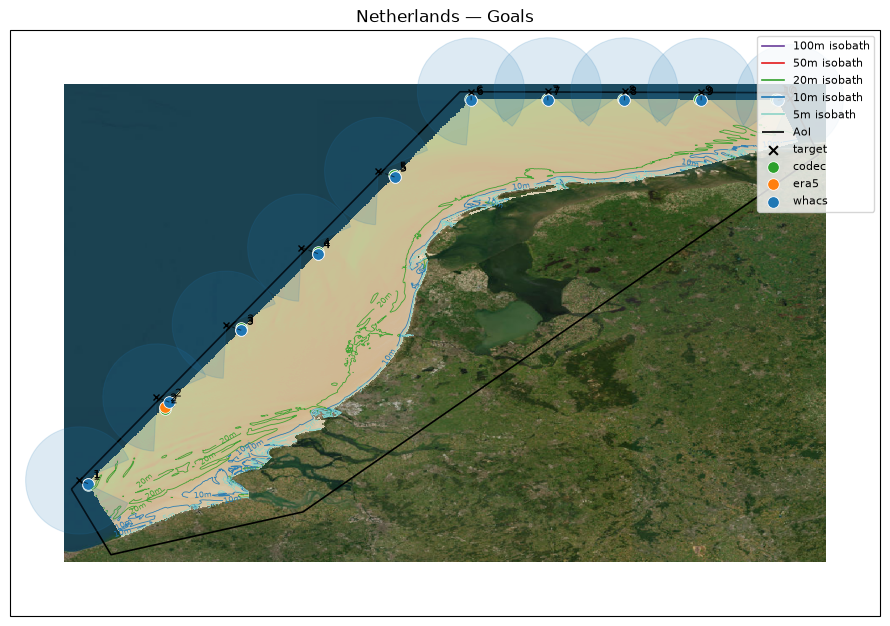

In [24]:
# Optionally edit this dictionary and rerun this cell.
direction_overrides: dict[str, list[float]] = {
    "1": [-245, 67],
    "6": [-175, 130],
    "10": [-125, 203],
}

goals_final = json.loads(json.dumps(goals))
for goal_id, angles in direction_overrides.items():
    if goal_id not in goals_final:
        raise KeyError(f"Unknown goal_id in direction_overrides: {goal_id}")
    if len(angles) != 2 or angles[0] >= angles[1]:
        raise ValueError(
            f"{goal_id}: angles must be [left, right] with left < right, got {angles}"
        )
    goals_final[goal_id]["angles"] = [float(angles[0]), float(angles[1])]

fig, ax = plot.plot_base_map(
    title="Goals",
    show_topobathy=True,
    show_satellite=True,
)
plot.plot_sectors(targets, goals_final, boundary_snaps, ax)
targets.plot(ax=ax, color="black", markersize=40, marker="x", label="target")

plot.plot_points(
    hc.hindcast_snaps_gdf(goals_final),
    ax,
    color_col="catalog",
    label_col="goal_id",
    color_map=plot.HINDCAST_COLORS,
)

minx, miny, maxx, maxy = aoi.total_bounds
pad = 0.4
ax.set_xlim(minx - pad, maxx + pad)
ax.set_ylim(miny - pad, maxy + pad)
ax.set_aspect("equal", adjustable="box")

fig.tight_layout()

## Save goals JSON and QGIS GeoPackage

After saving, update the case JSON with your selected goals JSON path:

```json
"simulations": {
    "goals_file": "../data/Goals/<Case>_Goals.json"
}
```

Relative to `HyWaves/` (see `utils.config.resolve()`) -- the shared `data/`
folder is one level up, so this is `../data/Goals/...`, not
`inputs/goals/...`.

In [25]:
goals_to_save = goals_final if "goals_final" in locals() else goals

goals_out_path.parent.mkdir(parents=True, exist_ok=True)

with goals_out_path.open("w", encoding="utf-8") as f:
    json.dump({"goals": goals_to_save}, f, indent=4)
    f.write("\n")

hc.save_goals_gpkg(
    goals_to_save, targets, boundary_snaps, goals_gpkg_path, ring=ring_gdf
)

print(f"Wrote {len(goals_to_save)} goal(s) to:")
print(f"  {goals_out_path}")
print(f"  {goals_gpkg_path}")
print(
    "\nGPKG layers: targets, boundary_snaps, sectors, links, buffer_ring, "
    "codec, era5, whacs"
)
print(json.dumps({"goals": goals_to_save}, indent=4))

Wrote 10 goal(s) to:
  /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/Goals/Netherlands_Goals.json
  /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/Goals/Netherlands_Goals.gpkg

GPKG layers: targets, boundary_snaps, sectors, links, buffer_ring, codec, era5, whacs
{
    "goals": {
        "1": {
            "target": {
                "longitude": 2.5,
                "latitude": 51.5
            },
… (297 more lines not shown)
